# Turtle Breakout 07 — what happens after a losing turtle trade, and does stop-and-reverse pay?

Pre-registration: `discussions/Turtle_Breakout/009_claude_tb07_preregistration.md`. Code: `src/data_engineering/modeling/turtle_reverse.py`.

Original daily turtle (TB 01 rules, long only). At every **losing stop exit** ($R<0$) a **short** is opened at the exit fill, with mirrored exits: fixed stop = price + 2 ATR, trailing = 10-day high, and closed at the next long breakout. Costs: taker 0.05% + 1 bp per side, funding.
**Decision (confirmation = BTC/ETH/SOL/XRP from 2020-10-15):** G1 mean $R_{rev}$ > 0 with month-cluster 95% lower bound > 0; G2 above random flat-day shorts (2,000 runs, empirical p < 0.05). Discovery = 26 other perps, same statistics, reported.

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB07_SYNTHETIC=1`.

In [1]:
import os, sys, json, time, gc, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, turtle_reverse as tr

SYNTHETIC = os.getenv('TB07_SYNTHETIC', '0') == '1'
P = tb.Params(); RP = tr.RParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb07-')) / '07'; RP = tr.RParams(n_null=500, n_boot=300)
    ASSETS = ['BTC', 'ETH', 'SOL', 'XRP', 'BNB', 'DOGE', 'ADA', 'LINK']
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '07'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    ASSETS = list(tf.UNIVERSE)
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_reverse.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print(json.dumps(tr.registration(RP), indent=1, default=str))

OK
{
 "stop_atr": 2.0,
 "side_cost": 0.0006,
 "n_null": 2000,
 "n_boot": 2000,
 "alpha": 0.05,
 "seed": 20261030,
 "status": "PREREGISTERED_TB009",
 "version": "TB07-0.1.0",
 "horizons_days": [
  1,
  3,
  5,
  10
 ],
 "losing_exit": "long closed by a stop with net R < 0",
 "reverse": "short at the exit fill; fixed stop +2 ATR, trailing 10-day high; closed at the next long entry",
 "gates": {
  "G1": "confirmation: mean R_rev > 0 with month-cluster bootstrap 95% lower bound > 0",
  "G2": "confirmation: mean R_rev above random flat-day shorts, empirical one-sided p < 0.05 (2,000 runs)",
  "verdict": "REVERSE_PAYS (G1 & G2) / BEATS_RANDOM_SHORTS_ONLY (G2) / NO_EDGE"
 },
 "reported": [
  "discovery set, same statistics",
  "event study vs winners and random flat days",
  "fixed-horizon shorts",
  "long-only vs long + reverse curves",
  "by exit reason, by year, by asset"
 ]
}


## 1. Long trades, reversals, random flat-day shorts and the event study, asset by asset

In [2]:
TS, RS, POOLS, ES, COV = [], [], {}, [], []
for i, a in enumerate(ASSETS):
    t1 = time.time()
    if SYNTHETIC:
        b = tb.synthetic_5m(1800, seed=70 + i, trend=0.0, start='2020-01-01'); f = tb.synthetic_funding(b, 0.0001)
    else:
        pu = DATA / f'{a}USDT_um_1m.parquet'
        if not pu.exists():
            COV.append({'asset': a, 'status': 'no perp file'}); print(a, 'missing'); continue
        b, _ = tf.load_um(pu)
        fpth = DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        f = tb.funding_events(pd.read_parquet(fpth)) if fpth.exists() else None
    d = tb.prepare_asset(a, b, f, P)
    conf = a in tf.CONFIRM_ASSETS
    start = tb.COMMON_START if conf else b.index[0] + pd.Timedelta(days=30)
    end = tr.TON_CUTOFF if a == 'TON' else None
    T = tf.run_trades(d, P, start, end)
    if not len(T):
        COV.append({'asset': a, 'status': 'no trades'}); continue
    k_lo = max(0, int(tb.period_id(pd.DatetimeIndex([start]), 'day')[0]) - d.pid0)
    k_hi = None if end is None else int(tb.period_id(pd.DatetimeIndex([end]), 'day')[0]) - d.pid0
    R = tr.reverse_trades(d, T, RP)
    if end is not None and len(R):
        R = R[R.rev_exit_time < end]
    pool = tr.random_short_pool(d, T, k_lo, RP, k_hi)
    E = tr.event_study(d, T, pool, RP)
    s = 'confirm' if conf else 'discovery'
    T = T.assign(set=s); R = R.assign(set=s); E = E.assign(set=s); pool = pool.assign(set=s)
    TS.append(T); RS.append(R); POOLS[a] = pool; ES.append(E)
    COV.append({'asset': a, 'status': 'ok', 'set': s, 'first_bar': b.index[0], 'last_bar': b.index[-1], 'longs': len(T),
                'losing_stop_exits': len(tr.losing_exits(T)), 'reversals': len(R), 'flat_days': len(pool),
                'sum_R_long': float(T.R.sum()), 'sum_R_rev': float(R.R_rev.sum()) if len(R) else 0.0, 'funding': f is not None})
    print(f"{a}: {len(T)} longs, {len(R)} reversals, {time.time() - t1:.0f}s")
    del b, d; gc.collect()
COV = pd.DataFrame(COV); display(COV)
TALL = pd.concat(TS, ignore_index=True); RALL = pd.concat(RS, ignore_index=True); EALL = pd.concat(ES, ignore_index=True)

BTC: 49 longs, 30 reversals, 4s
ETH: 44 longs, 23 reversals, 3s
SOL: 46 longs, 26 reversals, 3s
XRP: 41 longs, 26 reversals, 3s
BNB: 55 longs, 32 reversals, 4s
DOGE: 44 longs, 25 reversals, 4s
ADA: 51 longs, 37 reversals, 4s
LINK: 58 longs, 39 reversals, 4s
DOT: 45 longs, 32 reversals, 4s
LTC: 54 longs, 40 reversals, 4s
BCH: 52 longs, 36 reversals, 4s
UNI: 46 longs, 31 reversals, 3s
NEAR: 44 longs, 27 reversals, 3s
APT: 32 longs, 25 reversals, 2s
ARB: 26 longs, 17 reversals, 2s
OP: 34 longs, 24 reversals, 3s
SUI: 28 longs, 17 reversals, 2s
FIL: 41 longs, 28 reversals, 3s
ATOM: 52 longs, 36 reversals, 4s
ETC: 50 longs, 37 reversals, 4s
INJ: 34 longs, 22 reversals, 3s
AAVE: 52 longs, 37 reversals, 3s
TON: 39 longs, 35 reversals, 1s
WIF: 19 longs, 11 reversals, 2s
HBAR: 33 longs, 25 reversals, 3s
XLM: 53 longs, 36 reversals, 5s
SEI: 22 longs, 13 reversals, 2s
TIA: 24 longs, 18 reversals, 2s
ENA: 20 longs, 13 reversals, 2s
WLD: 26 longs, 17 reversals, 2s


,asset,status,set,first_bar,last_bar,longs,losing_stop_exits,reversals,flat_days,sum_R_long,sum_R_rev,funding
0,BTC,ok,confirm,2020-01-01 00:05:00+00:00,2026-10-24 00:00:00+00:00,49,30,30,1306,35.858903,8.952516,True
1,ETH,ok,confirm,2020-01-01 00:05:00+00:00,2026-10-24 00:00:00+00:00,44,24,23,1336,29.657670,1.479071,True
2,SOL,ok,confirm,2020-09-14 07:05:00+00:00,2026-10-24 00:00:00+00:00,46,26,26,1351,59.898002,3.347844,True
3,XRP,ok,confirm,2020-01-06 08:25:00+00:00,2026-10-24 00:00:00+00:00,41,27,26,1553,71.415046,4.021594,True
4,BNB,ok,discovery,2020-02-10 08:05:00+00:00,2026-10-24 00:00:00+00:00,55,32,32,1403,40.237476,-3.856305,True
5,DOGE,ok,discovery,2020-07-10 09:05:00+00:00,2026-10-24 00:00:00+00:00,44,26,25,1556,69.839505,0.243001,True
6,ADA,ok,discovery,2020-01-31 08:05:00+00:00,2026-10-24 00:00:00+00:00,51,37,37,1634,54.222574,0.936465,True
7,LINK,ok,discovery,2020-01-17 08:05:00+00:00,2026-10-24 00:00:00+00:00,58,40,39,1525,10.442060,-0.262679,True
8,DOT,ok,discovery,2020-08-22 07:05:00+00:00,2026-10-24 00:00:00+00:00,45,32,32,1553,11.504475,3.599814,True
9,LTC,ok,discovery,2020-01-09 08:10:00+00:00,2026-10-24 00:00:00+00:00,54,40,40,1608,-11.272494,5.520005,True


## 2. Decision: stop-and-reverse on the confirmation set (binding), discovery reported

In [3]:
RESULTS = {}
for s, seed in (('confirm', RP.seed), ('discovery', RP.seed + 1)):
    R = RALL[RALL.set == s]
    counts = R.groupby('asset').size().to_dict()
    nm = tr.null_means(POOLS, counts, RP, seed)
    RESULTS[s] = tr.evaluate(R, nm, RP, seed); RESULTS[s]['null_draws'] = nm
DEC = {s: {k: v for k, v in r.items() if k != 'null_draws'} for s, r in RESULTS.items()}
DEC['verdict'] = DEC['confirm']['verdict']
print(json.dumps(DEC, indent=1, default=float))

{
 "confirm": {
  "reversals": 105,
  "mean_R_rev": 0.16953357266162325,
  "lo95": -0.13755748914986501,
  "hi95": 0.5290761812366078,
  "win_rate": 0.4095238095238095,
  "mean_R_rev_gross": 0.17576382024099127,
  "sum_R_rev": 17.801025129470442,
  "median_hold_days": 15.753472222222221,
  "mean_funding_bp": -0.4561005774722145,
  "share_closed_by_next_long": 0.0,
  "null_mean_R": -0.00975431244612826,
  "null_sd": 0.09182505126602472,
  "z": 1.9524942554983147,
  "p": 0.02948525737131434,
  "G1": "FAIL",
  "G2": "PASS",
  "verdict": "BEATS_RANDOM_SHORTS_ONLY"
 },
 "discovery": {
  "reversals": 710,
  "mean_R_rev": 0.03728263205073483,
  "lo95": -0.16014923138062362,
  "hi95": 0.25009693762553004,
  "win_rate": 0.4126760563380282,
  "mean_R_rev_gross": 0.04036740028148906,
  "sum_R_rev": 26.47066875602173,
  "median_hold_days": 12.996527777777779,
  "mean_funding_bp": 10.919047001297244,
  "share_closed_by_next_long": 0.0,
  "null_mean_R": -0.030936046553151117,
  "null_sd": 0.02808180

## 3. The event study: what price does after losing exits, winning exits and random flat days

In [4]:
EV = pd.concat([tr.event_table(EALL[EALL.set == s], RP).assign(set=s) for s in ('confirm', 'discovery')], ignore_index=True)
display(EV.round(3))
print('mean_move_atr: forward move in ATR (negative = price fell). short_R_net: net R of a short opened at the start and held exactly h days.')

,kind,h_days,n,mean_move_atr,move_lo95,move_hi95,mean_bp,share_down,short_R_net,short_lo95,short_hi95,set
0,after_loss,1,106,0.040,-0.201,0.260,26.125,0.453,-0.031,-0.142,0.086,confirm
1,after_loss,3,107,0.044,-0.319,0.395,6.494,0.514,-0.036,-0.202,0.139,confirm
2,after_loss,5,106,-0.064,-0.533,0.359,-85.733,0.519,0.020,-0.180,0.216,confirm
3,after_loss,10,107,-0.164,-0.725,0.445,-173.501,0.645,0.081,-0.202,0.350,confirm
4,after_win,1,73,0.245,0.042,0.449,185.853,0.342,-0.132,-0.231,-0.035,confirm
5,after_win,3,73,0.236,-0.139,0.593,127.062,0.425,-0.124,-0.310,0.071,confirm
6,after_win,5,73,0.431,0.006,0.852,271.491,0.397,-0.216,-0.440,-0.020,confirm
7,after_win,10,73,0.864,0.247,1.515,467.784,0.384,-0.418,-0.756,-0.119,confirm
8,random_flat,1,5543,0.010,-0.016,0.037,-1.828,0.498,-0.014,-0.028,-0.001,confirm
9,random_flat,3,5540,0.034,-0.045,0.119,-6.274,0.501,-0.024,-0.067,0.013,confirm


mean_move_atr: forward move in ATR (negative = price fell). short_R_net: net R of a short opened at the start and held exactly h days.


## 4. Breakdowns (reported)

In [5]:
def summ(g):
    return pd.Series({'n': len(g), 'mean_R_rev': g.R_rev.mean(), 'median_R_rev': g.R_rev.median(), 'win_rate': (g.R_rev > 0).mean(),
                      'sum_R_rev': g.R_rev.sum(), 'median_hold_d': g.hold_days.median(), 'share_R_rev_ge_2': (g.R_rev >= 2).mean()})
BY_REASON = RALL.groupby(['set', 'long_reason']).apply(summ); display(BY_REASON.round(3))
BY_EXIT = RALL.groupby(['set', 'rev_reason']).apply(summ); display(BY_EXIT.round(3))
BY_YEAR = RALL.assign(year=pd.DatetimeIndex(RALL.rev_time).year).groupby(['set', 'year']).apply(summ); display(BY_YEAR.round(3))
BY_ASSET = RALL[RALL.set == 'confirm'].groupby('asset').apply(summ); display(BY_ASSET.round(3))
BY_LOSS = RALL.assign(long_R_bucket=pd.cut(RALL.long_R, [-10, -1.0, -0.75, -0.5, -0.25, 0])).groupby(['set', 'long_R_bucket'], observed=True).apply(summ)
display(BY_LOSS.round(3))
top = RALL[RALL.set == 'confirm'].sort_values('R_rev', ascending=False)
if len(top):
    print('confirmation: share of total reverse R from the top 3 trades =', round(top.R_rev.head(3).sum() / top.R_rev.sum(), 2) if top.R_rev.sum() != 0 else np.nan)

n  mean_R_rev  median_R_rev  win_rate  sum_R_rev  median_hold_d  share_R_rev_ge_2
set       long_reason                                                                                            
confirm   fixed_stop         40.0       0.007        -0.080     0.425      0.273         16.288             0.000
          trail              65.0       0.270        -0.170     0.400     17.528         15.003             0.154
discovery fixed_stop        229.0      -0.052        -0.237     0.415    -11.862         14.125             0.048
          stop_same_period   41.0      -0.068        -0.033     0.171     -2.789          0.003             0.000
          trail             440.0       0.093        -0.204     0.434     41.122         13.306             0.061

,,n,mean_R_rev,median_R_rev,win_rate,sum_R_rev,median_hold_d,share_R_rev_ge_2
set,rev_reason,,,,,,,
confirm,stop,105.0,0.170,-0.105,0.410,17.801,15.753,0.095
discovery,stop,710.0,0.037,-0.155,0.413,26.471,12.997,0.054


n  mean_R_rev  median_R_rev  win_rate  sum_R_rev  median_hold_d  share_R_rev_ge_2
set       year                                                                                       
confirm   2020    3.0      -0.523        -0.780     0.333     -1.569         14.479             0.000
          2021   16.0       0.296        -0.028     0.500      4.733         18.627             0.000
          2022   19.0       0.487        -0.070     0.474      9.259         18.066             0.211
          2023   14.0      -0.169        -0.385     0.357     -2.371         15.300             0.000
          2024   20.0      -0.268        -0.275     0.400     -5.354         12.210             0.000
          2025   18.0      -0.081        -0.135     0.278     -1.462         16.464             0.056
          2026   15.0       0.971        -0.010     0.467     14.565         16.097             0.333
discovery 2020   55.0      -0.406        -0.673     0.182    -22.317          8.434             0.055
          2021   69.0      -0.052        -0.579     0.377     -3.590         10.868             0.058
          2022   79.0       0.312         0.176     0.570     24.649         17.875             0.076
          2023  100.0       0.013        -0.126     0.420      1.257         15.326             0.060
          2024  153.0      -0.012        -0.237     0.418     -1.904         12.965             0.020
          2025  117.0      -0.083        -0.088     0.479     -9.766         15.413             0.009
          2026  137.0       0.278        -0.038     0.365     38.142         10.750             0.109

,n,mean_R_rev,median_R_rev,win_rate,sum_R_rev,median_hold_d,share_R_rev_ge_2
asset,,,,,,,
BTC,30.0,0.298,-0.143,0.400,8.953,17.061,0.100
ETH,23.0,0.064,-0.090,0.435,1.479,15.764,0.043
SOL,26.0,0.129,-0.342,0.423,3.348,12.590,0.154
XRP,26.0,0.155,-0.135,0.385,4.022,16.038,0.077


n  mean_R_rev  median_R_rev  win_rate  sum_R_rev  median_hold_d  share_R_rev_ge_2
set       long_R_bucket                                                                                       
confirm   (-10.0, -1.0]   43.0      -0.054        -0.181     0.372     -2.334         15.753             0.000
          (-1.0, -0.75]   20.0       0.227        -0.086     0.400      4.546         16.118             0.100
          (-0.75, -0.5]   14.0       0.232        -0.035     0.500      3.247         11.396             0.143
          (-0.5, -0.25]   16.0       0.054        -0.483     0.188      0.867         14.757             0.125
          (-0.25, 0.0]    12.0       0.956         0.231     0.750     11.474         21.455             0.333
discovery (-10.0, -1.0]  238.0      -0.040        -0.245     0.429     -9.435         13.283             0.046
          (-1.0, -0.75]  161.0       0.005        -0.191     0.391      0.742         13.955             0.037
          (-0.75, -0.5]  130.0       0.110        -0.106     0.462     14.276         13.306             0.069
          (-0.5, -0.25]   96.0       0.026        -0.351     0.396      2.460         12.639             0.052
          (-0.25, 0.0]    85.0       0.217        -0.031     0.353     18.428          7.153             0.082

confirmation: share of total reverse R from the top 3 trades = 0.67


## 5. Curves: long only vs long + reverse (confirmation, 1R per trade, booked at exit)

,total_R,max_dd_R,sharpe_daily_R
long_only,196.830,-12.808,1.106
reverse_only,17.801,-9.548,0.529
long_plus_reverse,214.631,-12.406,1.185


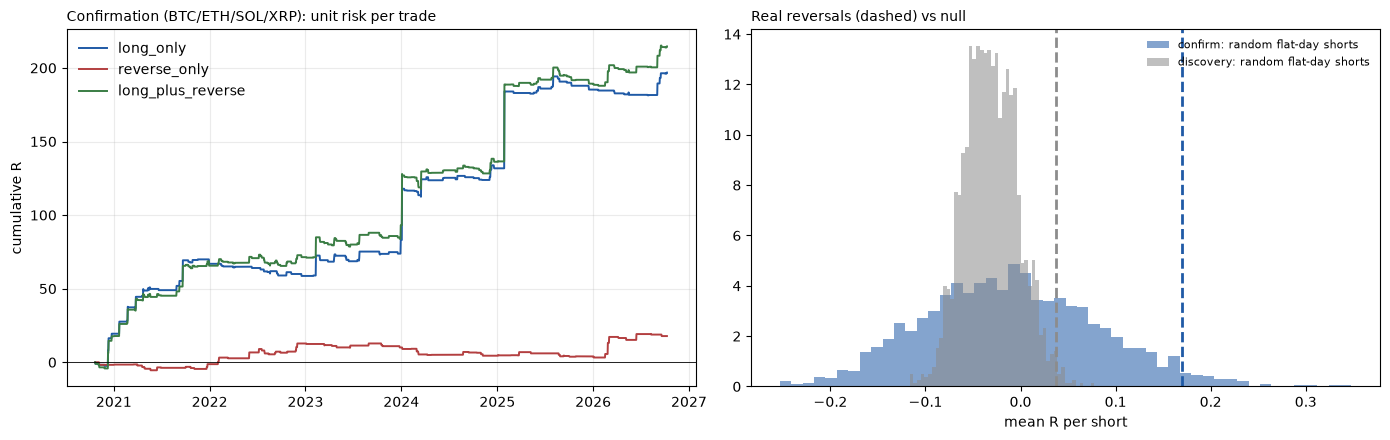

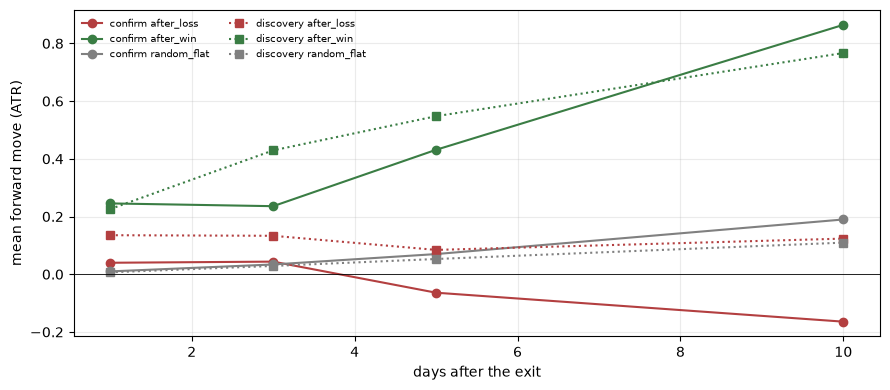

In [6]:
Tc = TALL[TALL.set == 'confirm']; Rc = RALL[RALL.set == 'confirm']
CUR = tr.curves(Tc, Rc)
d_long = CUR.long_only.diff().fillna(CUR.long_only.iloc[0]); d_both = CUR.long_plus_reverse.diff().fillna(CUR.long_plus_reverse.iloc[0])
sh = lambda x: float(x.mean() / x.std(ddof=1) * np.sqrt(365)) if x.std() > 0 else np.nan
CSUM = pd.DataFrame({'total_R': CUR.iloc[-1], 'max_dd_R': [tr.max_dd(CUR[c]) for c in CUR],
                     'sharpe_daily_R': [sh(CUR[c].diff().fillna(CUR[c].iloc[0])) for c in CUR]})
display(CSUM.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for c, col in zip(CUR, ('#1f5aa6', '#b33f40', '#3a7d44')):
    axes[0].plot(CUR.index, CUR[c], label=c, color=col, lw=1.4)
axes[0].axhline(0, color='k', lw=0.6); axes[0].set_ylabel('cumulative R'); axes[0].legend(frameon=False); axes[0].grid(alpha=0.25)
axes[0].set_title('Confirmation (BTC/ETH/SOL/XRP): unit risk per trade', loc='left', fontsize=10)
for s, col in (('confirm', '#1f5aa6'), ('discovery', '0.55')):
    nm = RESULTS[s]['null_draws']
    axes[1].hist(nm, bins=50, alpha=0.55, color=col, density=True, label=f'{s}: random flat-day shorts')
    axes[1].axvline(RESULTS[s].get('mean_R_rev', np.nan), color=col, lw=2, ls='--')
axes[1].set_xlabel('mean R per short'); axes[1].legend(frameon=False, fontsize=8); axes[1].set_title('Real reversals (dashed) vs null', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for s, mk in (('confirm', 'o'), ('discovery', 's')):
    for kind, col in (('after_loss', '#b33f40'), ('after_win', '#3a7d44'), ('random_flat', '0.5')):
        g = EV[(EV.set == s) & (EV.kind == kind)]
        ax.plot(g.h_days, g.mean_move_atr, marker=mk, color=col, ls='-' if s == 'confirm' else ':', label=f'{s} {kind}')
ax.axhline(0, color='k', lw=0.6); ax.set_xlabel('days after the exit'); ax.set_ylabel('mean forward move (ATR)'); ax.legend(fontsize=7, frameon=False, ncol=2); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Save

In [7]:
import platform
DEC_OUT = {**DEC, 'registration': tr.registration(RP), 'synthetic': SYNTHETIC}
(OUT / '07_decision.json').write_text(json.dumps(DEC_OUT, indent=1, default=str))
COV.to_csv(OUT / '07_coverage.csv', index=False); EV.to_csv(OUT / '07_event_study.csv', index=False)
RALL.to_csv(OUT / '07_reversals.csv', index=False)
pd.concat([BY_REASON.assign(table='long_reason'), BY_EXIT.assign(table='rev_reason')]).to_csv(OUT / '07_by_reason.csv')
BY_YEAR.to_csv(OUT / '07_by_year.csv'); BY_ASSET.to_csv(OUT / '07_by_asset.csv'); BY_LOSS.to_csv(OUT / '07_by_long_R.csv')
CSUM.to_csv(OUT / '07_curves_summary.csv'); CUR.to_csv(OUT / '07_curves_daily.csv')
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '07_manifest.json').write_text(json.dumps({'version': tr.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'assets': ASSETS, 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\07
VERDICT: BEATS_RANDOM_SHORTS_ONLY
